# 07d The SARIMA family

SARIMA was the best classical model in 07a (median RMSE 4.445, MAE 3.522 on the 150 products), but we never tried to
make it better. Here we do, with the short list of tweaks fixed in `docs/PREREGISTRATION_TS.md`: a log or Box-Cox
transform, clipping extreme training days, Fourier terms for the yearly pattern, a Christmas dummy, SNAP, event and
price regressors (which turn SARIMA into SARIMAX), and a fix for fits that do not converge. We add them one at a
time and keep a tweak only if it lowers both RMSE and MAE on the three validation origins. The scored origins are
shown next to every step, but nothing is chosen on them. Damped ETS and seasonal naive get the same treatment where
the plan allows, so all four contenders from this notebook are tuned the same way.

## Load

The same 150 products, the same 07a orders, and nine origins: three for validation (2015-09-13, 2015-10-11 and the
warm-up 2015-11-08) and the six scored ones. Every fit is saved per product, so running the notebook again only
reads the files; set `RERUN = True` to fit everything again (about two hours on our laptop).

In [1]:
import os, sys, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")    # the joblib workers need src/ too
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from config import ROOT, PROCESSED, TABLES, FIGS, EVAL_ORIGINS, CATEGORIES, FIG_STYLE, COLORS
import ts_models as tm
from evaluation import mase_scales

RERUN = False
N_JOBS = 10
FITS = PROCESSED / "ts_fits"
plt.rcParams.update(FIG_STYLE)
written = []

inp = tm.load_inputs()
series, flags, prices, orders, sample = inp["series"], inp["flags"], inp["prices"], inp["orders"], inp["sample"]
scales = mase_scales(inp["daily"], tm.ALL_ORIGINS)
print(len(series), "products")
print("validation origins:", [str(o.date()) for o in tm.VAL_ORIGINS])
print("scored origins:    ", [str(o.date()) for o in EVAL_ORIGINS])

150 products
validation origins: ['2015-09-13', '2015-10-11', '2015-11-08']
scored origins:     ['2015-12-06', '2016-01-03', '2016-01-31', '2016-02-28', '2016-03-27', '2016-04-24']


## How a step is run and judged

`run` fits one setting on every product at all nine origins. `scores` gives two sets of medians: validation, which
goes through `tm.for_tuning` and is the only thing a decision looks at, and scored, which we print for the record.
A tweak is kept if it lowers both validation RMSE and validation MAE.

In [2]:
def exog_of(o):
    names = [f"fourier{o['fourier']}"] if o.get("fourier") else []
    names += ["christmas"] * bool(o.get("christmas")) + ["snap", "event"] * bool(o.get("snapev"))
    return names + ["rel_price"] * bool(o.get("price"))


def name_of(o, base):
    tags = ([o["how"]] if o.get("how") else []) + ["clip"] * bool(o.get("clip"))
    tags += ([f"f{o['fourier']}"] if o.get("fourier") else []) + ["xmas"] * bool(o.get("christmas"))
    tags += ["snapev"] * bool(o.get("snapev")) + ["price"] * bool(o.get("price")) + ["fix"] * bool(o.get("fix"))
    return "_".join([base] + tags) if tags else base + "_base"


def run(o, base="sarima"):
    def spec(i):
        if base == "ets":
            return {"kind": "ets", "fit_days": None, **{k: o[k] for k in ["how", "clip"] if o.get(k)}}
        if base == "naive":
            return {"kind": "naive", "fit_days": None}
        s = {"kind": "sarima", "exog": exog_of(o), **{k: o[k] for k in ["how", "clip", "fix"] if o.get(k)}}
        if base == "arimax":
            return {**s, "order": orders.loc[i, "arima_order"]}
        return {**s, "order": orders.loc[i, "sarima_order"], "sorder": orders.loc[i, "sarima_sorder"]}
    name = name_of(o, base)
    t0 = time.time()
    fc = tm.run_model(name, spec, series, tm.ALL_ORIGINS, FITS, flags, prices, N_JOBS, RERUN)
    return name, fc, time.time() - t0


def scores(fc):
    """Validation medians (to choose with) and scored medians (to report only)."""
    val = tm.per_item(tm.item_scores(tm.for_tuning(fc), inp["actuals"], scales), tm.VAL_ORIGINS)
    sco = tm.per_item(tm.item_scores(tm.for_scoring(fc), inp["actuals"], scales), EVAL_ORIGINS)
    return tm.medians(val).iloc[0], tm.medians(sco).iloc[0]


rows, fcs = [], {}

def step(label, o, base="sarima", family="SARIMA"):
    name, fc, secs = run(o, base)
    fcs[name] = fc
    v, s = scores(fc)
    st = tm.fit_stats(fc).iloc[0]
    rows.append({"family": family, "step": label, "model": name, "kept": False,
                 **{f"val_{k}": v[k] for k in v.index}, **{f"scored_{k}": s[k] for k in s.index},
                 "fallback_rate": st["fallback_rate"], "not_converged_rate": st["not_converged_rate"]})
    print(f"{label:<26} val RMSE {v['rmse']:.3f} MAE {v['mae']:.3f} MAPE {v['mape']:.3f} | "
          f"scored RMSE {s['rmse']:.3f} MAE {s['mae']:.3f} MAPE {s['mape']:.3f} | not converged {st['not_converged_rate']:.0%} ({secs / 60:.1f} min)")
    return v


def helps(new, old):
    return new["rmse"] < old["rmse"] and new["mae"] < old["mae"]


def not_worse(new, old):
    return new["rmse"] <= old["rmse"] and new["mae"] <= old["mae"]


def try_tweak(state, cands, base="sarima", family="SARIMA", rule=helps):
    """Run each candidate on top of what is kept so far; keep the best one if the rule says so."""
    res = [(lab, o, step(lab, {**state["cur"], **o}, base, family)) for lab, o in cands]
    lab, o, v = min(res, key=lambda r: (r[2]["rmse"], r[2]["mae"]))
    keep = rule(v, state["best"])
    for r in rows[-len(cands):]:
        r["kept"] = bool(keep and r["step"] == lab)
    if keep:
        state["cur"].update(o)
        state["best"] = v
    print("   ->", f"kept {lab}" if keep else "nothing kept")
    return res

## SARIMA, one tweak at a time

The order is the one fixed in the plan. Each line is a full run on 150 products and nine origins.

In [3]:
sar = {"cur": {}, "best": None}
sar["best"] = step("SARIMA as in 07a", {})
try_tweak(sar, [("+ log1p", {"how": "log1p"}), ("+ Box-Cox", {"how": "boxcox"})])
try_tweak(sar, [("+ clipping", {"clip": True})])
four = try_tweak(sar, [(f"+ Fourier K={k}", {"fourier": k}) for k in (1, 2, 3)])
best_k = min(four, key=lambda r: (r[2]["rmse"], r[2]["mae"]))[1]["fourier"]
try_tweak(sar, [("+ Christmas dummy", {"christmas": True})], rule=not_worse)      # the one exception in the plan
try_tweak(sar, [("+ SNAP and event days", {"snapev": True})])
try_tweak(sar, [("+ relative price", {"price": True})])
try_tweak(sar, [("+ convergence fix", {"fix": True})])
final = dict(sar["cur"])
print("\nkept:", final if final else "nothing")

SARIMA as in 07a           val RMSE 4.697 MAE 3.814 MAPE 0.647 | scored RMSE 4.445 MAE 3.522 MAPE 0.603 | not converged 30% (0.0 min)


+ log1p                    val RMSE 4.775 MAE 3.922 MAPE 0.563 | scored RMSE 4.649 MAE 3.657 MAPE 0.544 | not converged 37% (0.0 min)


+ Box-Cox                  val RMSE 4.646 MAE 3.815 MAPE 0.589 | scored RMSE 4.665 MAE 3.629 MAPE 0.573 | not converged 32% (0.0 min)
   -> nothing kept


+ clipping                 val RMSE 4.700 MAE 3.814 MAPE 0.640 | scored RMSE 4.445 MAE 3.490 MAPE 0.602 | not converged 30% (0.0 min)
   -> nothing kept


+ Fourier K=1              val RMSE 4.600 MAE 3.676 MAPE 0.628 | scored RMSE 4.646 MAE 3.677 MAPE 0.612 | not converged 46% (0.0 min)


...

+ Fourier K=3              val RMSE 4.662 MAE 3.731 MAPE 0.625 | scored RMSE 4.569 MAE 3.589 MAPE 0.606 | not converged 58% (0.0 min)
   -> kept + Fourier K=1


+ Christmas dummy          val RMSE 4.670 MAE 3.681 MAPE 0.628 | scored RMSE 4.515 MAE 3.536 MAPE 0.610 | not converged 60% (0.0 min)
   -> nothing kept


+ SNAP and event days      val RMSE 4.676 MAE 3.714 MAPE 0.631 | scored RMSE 4.578 MAE 3.625 MAPE 0.610 | not converged 63% (0.0 min)
   -> nothing kept


+ relative price           val RMSE 4.776 MAE 3.832 MAPE 0.639 | scored RMSE 4.774 MAE 3.737 MAPE 0.628 | not converged 57% (0.0 min)
   -> nothing kept


+ convergence fix          val RMSE 4.625 MAE 3.676 MAPE 0.631 | scored RMSE 4.583 MAE 3.650 MAPE 0.608 | not converged 0% (0.0 min)
   -> nothing kept

kept: {'fourier': 1}


## The contenders from this family

The SARIMA contender keeps only the tweaks that do not add regressors. The SARIMAX contender adds the regressors
that were kept; if none was kept, it uses all of them (Fourier with the best K, Christmas, SNAP, events, price), as
the plan says. ARIMAX puts the same regressors on the 07a ARIMA orders, with nothing else changed. It is a building
block, not a contender.

In [4]:
REGS = ["fourier", "christmas", "snapev", "price"]
sarima_o = {k: v for k, v in final.items() if k not in REGS}
if any(k in final for k in REGS):
    sarimax_o, all_regs = final, False
else:
    sarimax_o, all_regs = {**sarima_o, "fourier": best_k, "christmas": True, "snapev": True, "price": True}, True
arimax_o = {k: v for k, v in sarimax_o.items() if k in REGS}
print("SARIMA contender: ", name_of(sarima_o, "sarima"))
print("SARIMAX contender:", name_of(sarimax_o, "sarima"), "(all regressors, none was kept)" if all_regs else "")
print("ARIMAX:           ", name_of(arimax_o, "arimax"))
step("contender: SARIMA", sarima_o, family="contender")
step("contender: SARIMAX", sarimax_o, family="contender")
step("building block: ARIMAX", arimax_o, base="arimax", family="building block")
contenders = {"sarima": name_of(sarima_o, "sarima"), "sarimax": name_of(sarimax_o, "sarima"),
              "arimax": name_of(arimax_o, "arimax")}

SARIMA contender:  sarima_base
SARIMAX contender: sarima_f1 
ARIMAX:            arimax_f1


contender: SARIMA          val RMSE 4.697 MAE 3.814 MAPE 0.647 | scored RMSE 4.445 MAE 3.522 MAPE 0.603 | not converged 30% (0.0 min)


contender: SARIMAX         val RMSE 4.600 MAE 3.676 MAPE 0.628 | scored RMSE 4.646 MAE 3.677 MAPE 0.612 | not converged 46% (0.0 min)


building block: ARIMAX     val RMSE 4.939 MAE 3.936 MAPE 0.656 | scored RMSE 4.801 MAE 3.866 MAPE 0.637 | not converged 7% (0.0 min)


## Damped ETS and seasonal naive

ETS can take the transform and the clipping. Seasonal naive is the baseline and is not tuned.

In [5]:
ets = {"cur": {}, "best": None}
ets["best"] = step("ETS as in 07a", {}, base="ets", family="ETS")
try_tweak(ets, [("ETS + log1p", {"how": "log1p"}), ("ETS + Box-Cox", {"how": "boxcox"})], base="ets", family="ETS")
try_tweak(ets, [("ETS + clipping", {"clip": True})], base="ets", family="ETS")
contenders["ets"] = name_of(ets["cur"], "ets")
step("seasonal naive", {}, base="naive", family="baseline")
contenders["seasonal_naive"] = "naive_base"
print("ETS contender:", contenders["ets"])

ETS as in 07a              val RMSE 4.668 MAE 3.720 MAPE 0.624 | scored RMSE 4.498 MAE 3.511 MAPE 0.595 | not converged 0% (0.0 min)


ETS + log1p                val RMSE 4.675 MAE 3.756 MAPE 0.561 | scored RMSE 4.593 MAE 3.623 MAPE 0.547 | not converged 0% (0.0 min)


ETS + Box-Cox              val RMSE 4.606 MAE 3.682 MAPE 0.581 | scored RMSE 4.513 MAE 3.543 MAPE 0.560 | not converged 0% (0.0 min)
   -> kept ETS + Box-Cox


ETS + clipping             val RMSE 4.606 MAE 3.682 MAPE 0.582 | scored RMSE 4.508 MAE 3.539 MAPE 0.560 | not converged 0% (0.0 min)
   -> nothing kept


seasonal naive             val RMSE 6.165 MAE 4.857 MAPE 0.750 | scored RMSE 6.039 MAE 4.720 MAPE 0.753 | not converged 0% (0.0 min)
ETS contender: ets_boxcox


## The ablation table

Every setting we ran, in order, with its validation and its scored medians. `kept` marks the tweaks that passed the
rule. The scored columns were never used to decide anything.

In [6]:
abl = pd.DataFrame(rows)
abl.to_csv(TABLES / "ts_sarima_ablation.csv", index=False)
written.append(TABLES / "ts_sarima_ablation.csv")
show = ["family", "step", "kept", "val_rmse", "val_mae", "val_mape", "scored_rmse", "scored_mae", "scored_mape", "not_converged_rate"]
abl[show].round(3)

,family,step,kept,val_rmse,val_mae,val_mape,scored_rmse,scored_mae,scored_mape,not_converged_rate
0,SARIMA,SARIMA as in 07a,False,4.697,3.814,0.647,4.445,3.522,0.603,0.303
1,SARIMA,+ log1p,False,4.775,3.922,0.563,4.649,3.657,0.544,0.373
2,SARIMA,+ Box-Cox,False,4.646,3.815,0.589,4.665,3.629,0.573,0.319
3,SARIMA,+ clipping,False,4.700,3.814,0.640,4.445,3.490,0.602,0.302
4,SARIMA,+ Fourier K=1,True,4.600,3.676,0.628,4.646,3.677,0.612,0.459
5,SARIMA,+ Fourier K=2,False,4.610,3.697,0.629,4.551,3.567,0.608,0.540
6,SARIMA,+ Fourier K=3,False,4.662,3.731,0.625,4.569,3.589,0.606,0.583
7,SARIMA,+ Christmas dummy,False,4.670,3.681,0.628,4.515,3.536,0.610,0.600
8,SARIMA,+ SNAP and event days,False,4.676,3.714,0.631,4.578,3.625,0.610,0.635
9,SARIMA,+ relative price,False,4.776,3.832,0.639,4.774,3.737,0.628,0.568


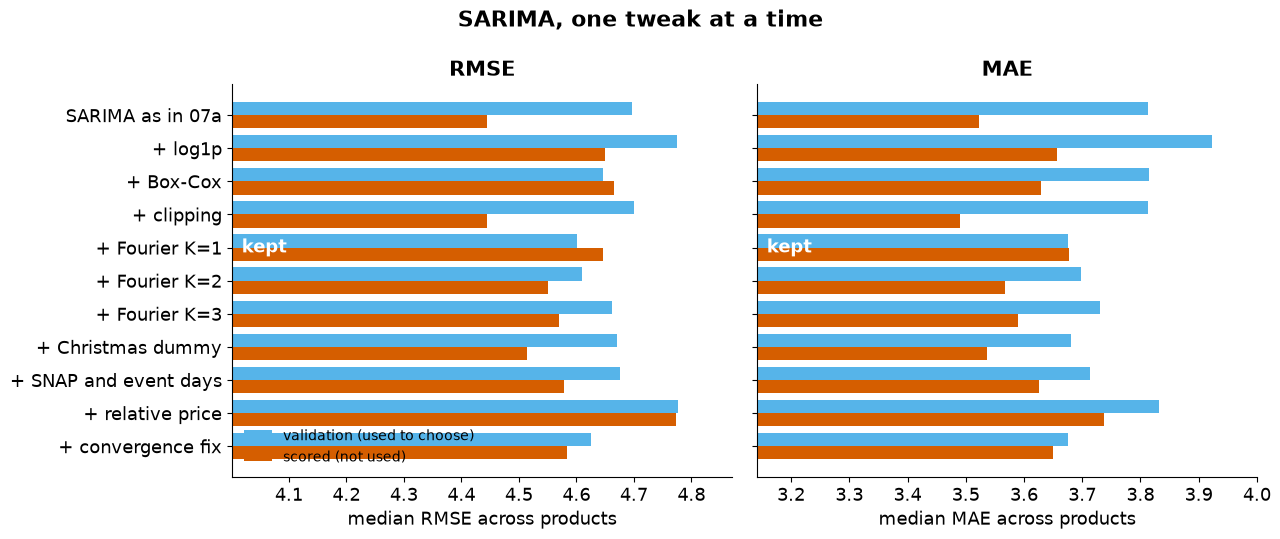

In [7]:
x = abl[abl["family"] == "SARIMA"].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, k, title in [(axes[0], "rmse", "RMSE"), (axes[1], "mae", "MAE")]:
    y = np.arange(len(x))[::-1]
    ax.barh(y + 0.2, x[f"val_{k}"], 0.4, color="#56B4E9", label="validation (used to choose)")
    ax.barh(y - 0.2, x[f"scored_{k}"], 0.4, color=COLORS["sarima"], label="scored (not used)")
    for yy, kept in zip(y, x["kept"]):
        if kept:
            ax.text(0.02, yy, "kept", va="center", color="white", fontweight="bold", transform=ax.get_yaxis_transform())
    ax.set_yticks(y, x["step"])
    lo = min(x[f"val_{k}"].min(), x[f"scored_{k}"].min())
    ax.set_xlim(lo * 0.9, max(x[f"val_{k}"].max(), x[f"scored_{k}"].max()) * 1.02)
    ax.set_xlabel(f"median {title} across products")
    ax.set_title(title)
axes[0].legend(loc="lower left", frameon=False, fontsize=10)
fig.suptitle("SARIMA, one tweak at a time", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "ts_sarima_ablation.png")
written.append(FIGS / "ts_sarima_ablation.png")
plt.show()

## What the regressors learned

We refit SARIMA with every regressor we tried (Fourier with the best K, Christmas, SNAP, events and relative price)
once per product at the warm-up origin, and keep each coefficient with its p-value. This is the full model, not the
contender: it shows what each regressor does even where it did not earn its place. To compare SNAP with the +10%
FOODS effect from 03, we turn the SNAP coefficient into a percentage of the product's typical day: the forecast at the
product's average level with and without SNAP. A product whose price never changed in the window has no price
coefficient.

In [8]:
def coefs(i, o):
    d = series[i]
    y, dt = tm.window(d["sales"], d["date"], tm.VAL_ORIGINS[-1])
    names = exog_of(o)
    z, back = tm.prepare(y, o.get("clip", False), o.get("how"))
    ex, _, kept = tm.drop_constant(tm.make_exog(dt, flags, names, prices[i]))
    res, ok = tm.fit_sarimax(z, orders.loc[i, "sarima_order"], orders.loc[i, "sarima_sorder"], ex,
                             maxiter=500 if o.get("fix") else None)
    cols = [tm.exog_columns(names)[k] for k in kept]
    at = [res.param_names.index(f"x{j + 1}") for j in range(len(cols))]       # statsmodels calls the regressors x1, x2, ...
    zbar = float(np.mean(z))
    out = pd.DataFrame({"item_id": i, "param": cols, "coef": np.asarray(res.params)[at],
                        "p_value": np.asarray(res.pvalues)[at], "converged": ok})
    out["effect_pct"] = [float(back(np.array([zbar + b]))[0] / back(np.array([zbar]))[0] - 1) for b in out["coef"]]
    return out

full_o = {**sarima_o, "fourier": best_k, "christmas": True, "snapev": True, "price": True}
coef = pd.concat(Parallel(n_jobs=N_JOBS)(delayed(coefs)(i, full_o) for i in series), ignore_index=True)
coef["category"] = coef["item_id"].str.split("_").str[0]
coef.to_csv(TABLES / "ts_sarimax_coefficients.csv", index=False)
written.append(TABLES / "ts_sarimax_coefficients.csv")
csum = coef.groupby(["param", "category"]).agg(n=("coef", "size"), median_coef=("coef", "median"),
                                               median_effect_pct=("effect_pct", "median"),
                                               share_p_below_5pct=("p_value", lambda p: (p < 0.05).mean()),
                                               share_positive=("coef", lambda c: (c > 0).mean())).reset_index()
csum.to_csv(TABLES / "ts_sarimax_coef_summary.csv", index=False)
written.append(TABLES / "ts_sarimax_coef_summary.csv")
csum.round(3)

,param,category,n,median_coef,median_effect_pct,share_p_below_5pct,share_positive
0,christmas,FOODS,50,-11.622,-0.787,0.320,0.000
1,christmas,HOBBIES,50,-4.530,-0.949,0.100,0.000
2,christmas,HOUSEHOLD,50,-4.835,-0.770,0.180,0.020
3,cos1,FOODS,50,-0.893,-0.058,0.280,0.360
4,cos1,HOBBIES,50,0.077,0.014,0.160,0.520
5,cos1,HOUSEHOLD,50,-0.465,-0.038,0.220,0.300
6,event,FOODS,50,-0.354,-0.026,0.160,0.400
7,event,HOBBIES,50,-0.303,-0.035,0.060,0.320
8,event,HOUSEHOLD,50,-0.266,-0.029,0.000,0.280
9,rel_price,FOODS,27,36.178,0.999,0.296,0.741


In [9]:
effects = pd.read_csv(TABLES / "explore_calendar_effects.csv").set_index("category")
if "snap" in set(coef["param"]):
    snap = coef[coef["param"] == "snap"].groupby("category")["effect_pct"].median()
    print("SNAP effect per product, median, from the SARIMAX coefficient, against the total in 03:")
    print(pd.DataFrame({"SARIMAX per product": snap, "03 on the total": effects["snap_vs_other_days"]}).round(3).to_string())

SNAP effect per product, median, from the SARIMAX coefficient, against the total in 03:
           SARIMAX per product  03 on the total
category                                       
FOODS                    0.081            0.100
HOBBIES                  0.051            0.035
HOUSEHOLD                0.049            0.039


## Fits that did not converge

07a used the statsmodels default of 50 optimiser steps, and 30% of SARIMA fits stopped before converging. Their
forecasts were kept, as here. This is how often each setting fell back or stopped early.

In [10]:
stats_ = abl[["family", "step", "model", "fallback_rate", "not_converged_rate"]]
print(stats_.round(3).to_string(index=False))

        family                   step            model  fallback_rate  not_converged_rate
        SARIMA       SARIMA as in 07a      sarima_base          0.000               0.303
        SARIMA                + log1p     sarima_log1p          0.000               0.373
        SARIMA              + Box-Cox    sarima_boxcox          0.001               0.319
        SARIMA             + clipping      sarima_clip          0.000               0.302
        SARIMA          + Fourier K=1        sarima_f1          0.001               0.459
        SARIMA          + Fourier K=2        sarima_f2          0.001               0.540
        SARIMA          + Fourier K=3        sarima_f3          0.000               0.583
        SARIMA      + Christmas dummy   sarima_f1_xmas          0.000               0.600
        SARIMA  + SNAP and event days sarima_f1_snapev          0.000               0.635
        SARIMA       + relative price  sarima_f1_price          0.001               0.568
        SA

## Save the contenders

The forecasts of the contenders and ARIMAX at all nine origins, in the long format of `classical_forecasts.parquet`,
plus the plain SARIMA refit (`sarima_base`) so a test can check it still equals 07a.

In [11]:
keep = [*contenders.items(), ("sarima_base", "sarima_base")]          # (label, setting); two labels can share a setting
out = pd.concat([fcs[s].assign(model=m, setting=s) for m, s in keep], ignore_index=True)
out = out.merge(inp["actuals"], on=["item_id", "date"]).merge(sample[["item_id", "category"]], on="item_id")
out.to_parquet(TABLES / "ts_sarima_forecasts.parquet", index=False)
written.append(TABLES / "ts_sarima_forecasts.parquet")
pd.Series(contenders).rename("setting").to_csv(TABLES / "ts_sarima_contenders.csv")
written.append(TABLES / "ts_sarima_contenders.csv")
print(out.groupby("model")["setting"].first().to_string())
assert out.groupby(["model", "item_id", "origin"]).size().eq(28).all()
assert out["forecast"].notna().all() and out["origin"].nunique() == 9

model
arimax              arimax_f1
ets                ets_boxcox
sarima            sarima_base
sarima_base       sarima_base
sarimax             sarima_f1
seasonal_naive     naive_base


## What we found

Most of the tweaks did not help, and the one that did on validation made the scored numbers worse.

The transforms behaved as we expected. log1p and Box-Cox both lower MAPE (validation 0.647 to 0.563 and 0.589),
because they forecast something closer to a median, but log1p raises RMSE and MAE, and Box-Cox lowers RMSE a little
(4.697 to 4.646) while MAE stays where it was (3.815). Neither lowers both, so neither was kept. Clipping extreme
training days changed almost nothing (RMSE 4.700, MAE 3.814): these busy products have few extreme days.

One Fourier pair for the yearly pattern was the only tweak that passed: validation RMSE 4.697 to 4.600 and MAE 3.814
to 3.676. That is the surprise of this notebook. On the six scored origins the same model is worse than plain SARIMA,
4.646 against 4.445 in RMSE. The validation windows run from mid-September to early December, when sales climb towards
the holidays, and a yearly curve helps there. The scored half-year runs from December to May, and the curve learned
from two years of data seems to pull the forecast the wrong way around the turn of the year. We keep it anyway,
because the rule says so and the scored origins are not allowed to choose. SARIMAX in the comparison is therefore
SARIMA with one Fourier pair, and plain SARIMA stays the 07a model.

The calendar regressors did not earn their place either. The Christmas dummy made validation RMSE worse (4.670), so
by the exception we wrote down it is dropped, although it does cut the scored error a little (4.515 against 4.646
without it) because it puts the closure day near zero. SNAP and event days made validation worse (4.676), and
relative price clearly worse (4.776). The convergence fix took non-converged fits from 46% to none at all, but the
forecasts barely moved and validation RMSE went up (4.625), so stopping early after 50 steps was not hurting accuracy.

The coefficients, from the full model with every regressor, tell a sensible story even where the regressors did not
help the forecast. SNAP days lift a typical FOODS product by 8.1%, against the +10% that 03 found on the FOODS total,
and HOBBIES and HOUSEHOLD by about 5% (03: 3.5% and 3.9%). SNAP is positive for 84% of FOODS products and significant
for 44%. Christmas takes 77% to 95% off a product's day, which is the store closure. Event days are slightly negative
(about 3%), as 03 found on the totals. Relative price has a positive median coefficient for two thirds of the products
that changed price, the opposite of what 03's weekly correlation suggested; with the level already differenced, it
seems to pick up price rises that came with a rising level rather than the price effect itself. So the regressors are
real effects, but most of them are small next to the day-to-day noise, and SARIMA's own weekly terms already cover
most of what they carry.

Damped ETS kept Box-Cox (validation RMSE 4.668 to 4.606, MAE 3.720 to 3.682); on the scored origins it is about the
same as before (4.513 against 4.498). Clipping on top changed nothing.

## What comes next

`07c_ar_ma_arma_arima` fits the simpler building blocks, `07f_theta_prophet_autots` the other contenders, and
`07h_time_series_comparison` puts them all side by side.

In [12]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\ts_sarima_ablation.csv 6 KB
outputs\figures\ts_sarima_ablation.png 89 KB
outputs\tables\ts_sarimax_coefficients.csv 79 KB
outputs\tables\ts_sarimax_coef_summary.csv 1 KB
outputs\tables\ts_sarima_forecasts.parquet 1,708 KB
outputs\tables\ts_sarima_contenders.csv 0 KB
